# AI Workforce Intelligence, Phase 1: exploration and baselines (CS3216 Time Series Analysis and Forecasting)

Phase 1 explores seven demand and cost series (BurstGPT LLM traffic, WildChat usage, wages and hosting prices) and sets simple benchmark forecasts that every later model must beat.

> **Where this fits.** This is **Phase 1** of 6.
> **Needs:** the processed data in `data/processed` (inside the zip).
> **Produces:** `outputs/phase1/handoff.json` (seasonal periods, differencing, decomposition, backtest settings) and the baseline scores, used by Phase 2.

> **How to use this notebook**
> 1. In Colab: *Runtime > Run all*. When asked, upload `ai-workforce-intel_colab.zip` (the same zip for all three notebooks).
> 2. `MODE = "show"` (default) only displays the finished results inside the zip: under 1 minute.
> 3. `MODE = "run"` recomputes **this phase only** (about 1 to 5 minutes on Colab), using the earlier phases' results in the zip.
> 4. Outside Colab, put the unzipped `ai-workforce-intel` folder (or the zip) next to this notebook.

In [1]:
# ---- Settings: change these, then Runtime > Run all ----
MODE = "show"       # "show": display the finished results in the bundle (under 1 minute)
                    # "run":  recompute Phase 1 first, then display the new results
RUN_FAST = True     # only for MODE = "run": True = --fast, False = full run
DRIVERS = None      # None = all drivers, or a list such as ["burst_tokens_total_daily"]
PHASE = 1

import os
MODE = os.environ.get("TSAF_MODE", MODE)  # used only by the automated test; ignore in Colab
print("Phase", PHASE, "| MODE =", MODE, "| RUN_FAST =", RUN_FAST, "| DRIVERS =", DRIVERS or "all")

Phase 1 | MODE = show | RUN_FAST = True | DRIVERS = all


### Helper functions
Small helpers used by every step: `step` turns any problem into a one-line message (so *Run all*
never stops), `show_img` and `show_table` display figures and tables at a readable size, and
`show_source` prints a real function from the project.

In [2]:
import contextlib, importlib, inspect, json, re, subprocess, sys, time, warnings
from pathlib import Path
import pandas as pd
from IPython.display import Image, Markdown, display

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 12)
pd.set_option("display.max_colwidth", 90)

@contextlib.contextmanager
def step(name):
    """Run one notebook step; a problem prints a short message instead of a traceback."""
    try:
        yield
    except FileNotFoundError as exc:
        print(f"[{name}] skipped: a result file is missing ({Path(str(exc.filename or exc)).name}).")
    except Exception as exc:
        print(f"[{name}] skipped: {type(exc).__name__}: {str(exc)[:200]}")

def show_img(path, width=900):
    """Display a saved PNG figure, or a short message if it does not exist."""
    path = Path(path)
    if not path.exists():
        print(f"No figure {path.name}; skipped.")
        return
    display(Image(filename=str(path), width=width))

def show_table(df, n=10, cols=None, digits=3):
    """Display the first n rows of a table, selected columns, rounded numbers."""
    if df is None or len(df) == 0:
        print("No rows to show.")
        return
    df = df[[c for c in cols if c in df.columns]] if cols else df
    display(df.head(n).round(digits).reset_index(drop=True))

def read_table(phase, name):
    """Read outputs/<phase>/tables/<name>.csv."""
    return pd.read_csv(Path("outputs") / phase / "tables" / f"{name}.csv")

def md_section(path, title):
    """Text of the '## ... title ...' section of a generated summary file (None if absent)."""
    text = Path(path).read_text(encoding="utf-8")
    pat = r"^## [^\n]*" + re.escape(title) + r"[^\n]*\n(.*?)(?=^## |\Z)"
    m = re.search(pat, text, flags=re.M | re.S)
    return m.group(1).strip() if m else None

def show_source(module, func, max_lines=25):
    """Print the source of module.func (first max_lines lines), or a short message."""
    try:
        obj = getattr(importlib.import_module(module), func)
        lines = inspect.getsource(obj).splitlines()
    except Exception as exc:
        print(f"Could not find {module}.{func}: {type(exc).__name__}; skipped.")
        return
    more = f"\n# ... {len(lines) - max_lines} more lines" if len(lines) > max_lines else ""
    display(Markdown(f"`{module}.{func}`\n```python\n" + "\n".join(lines[:max_lines]) + more + "\n```"))

## Setup 1: get the project
If the project folder is not here yet, the cell asks you to upload `ai-workforce-intel_colab.zip`
(about 10 MB), unzips it and moves into the folder. Outside Colab it looks for the folder (or the zip)
next to the notebook. The commented lines show how to unzip it from Google Drive instead.

In [3]:
def _is_project(p):
    return (p / "src" / "run_phase2.py").exists()

def _find_project():
    here = Path.cwd()
    for c in (here, here / "ai-workforce-intel", Path("/content/ai-workforce-intel")):
        if _is_project(c):
            return c
    return None

def _get_zip():
    if os.environ.get("TSAF_BUNDLE_PATH"):          # automated test: no upload dialog
        return Path(os.environ["TSAF_BUNDLE_PATH"])
    if Path("ai-workforce-intel_colab.zip").exists():
        return Path("ai-workforce-intel_colab.zip")
    try:
        from google.colab import files               # only exists inside Colab
    except ImportError:
        print("Not in Colab: place ai-workforce-intel_colab.zip or the unzipped folder next to this notebook.")
        return None
    print("Please upload ai-workforce-intel_colab.zip")
    uploaded = files.upload()
    return Path(next(iter(uploaded))) if uploaded else None

# Alternative: unzip from Google Drive instead of uploading (uncomment the two lines):
# from google.colab import drive; drive.mount("/content/drive")
# import zipfile; zipfile.ZipFile("/content/drive/MyDrive/ai-workforce-intel_colab.zip").extractall("/content")

PROJECT = None
with step("get the project"):
    PROJECT = _find_project()
    if PROJECT is None:
        zpath = _get_zip()
        if zpath is not None and zpath.exists():
            import zipfile
            base = Path("/content") if Path("/content").is_dir() else Path.cwd()
            zipfile.ZipFile(zpath).extractall(base)
            PROJECT = base / "ai-workforce-intel"
    if PROJECT is not None and _is_project(PROJECT):
        os.chdir(PROJECT)
        if str(PROJECT / "src") not in sys.path:
            sys.path.insert(0, str(PROJECT / "src"))
        print("Project ready: working folder is", Path.cwd().name)
    else:
        print("Project not found. Upload the zip and run this cell again.")

Project ready: working folder is ai-workforce-intel


## Setup 2: packages
Colab already has pandas, numpy, statsmodels, scikit-learn, matplotlib and pyarrow. This cell installs
only what is missing from `requirements.txt`, plus `xgboost` if it is missing. Prophet and torch are
optional and are never installed automatically.

In [4]:
IMPORT_NAME = {"scikit-learn": "sklearn"}
with step("packages"):
    wanted = []
    for line in Path("requirements.txt").read_text().splitlines():
        line = line.split("#")[0].strip()
        if line:
            wanted.append(re.split(r"[<>=!~ ]", line)[0])
    missing = []
    for pkg in wanted + ["xgboost"]:
        try:
            importlib.import_module(IMPORT_NAME.get(pkg, pkg))
        except ImportError:
            missing.append(pkg)
    if missing:
        print("Installing:", ", ".join(missing))
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "--disable-pip-version-check", *missing], check=False)
    else:
        print("All required packages are already installed.")
    import numpy, statsmodels, sklearn, matplotlib
    print(f"Python {sys.version.split()[0]} | pandas {pd.__version__} | numpy {numpy.__version__} | "
          f"statsmodels {statsmodels.__version__} | scikit-learn {sklearn.__version__} | matplotlib {matplotlib.__version__}")
    import optional
    for name, ok in [("xgboost", optional.has_xgboost()), ("prophet", optional.has_prophet()), ("torch (LSTM)", optional.has_torch())]:
        print(f"  optional {name:13s}: {'available' if ok else 'not installed (model skipped)'}")

All required packages are already installed.
Python 3.11.9 | pandas 3.0.5 | numpy 2.4.6 | statsmodels 0.15.0 | scikit-learn 1.9.0 | matplotlib 3.11.1


  optional xgboost      : available
  optional prophet      : not installed (model skipped)
  optional torch (LSTM) : available


## Setup 3: seeds and project layout
All randomness uses seed 42, so a rerun gives the same numbers.

In [5]:
with step("seeds and tree"):
    import random, numpy as np
    random.seed(42)
    np.random.seed(42)
    for top in sorted(p for p in Path(".").iterdir() if p.is_dir() and not p.name.startswith(".")):
        subs = sorted(q.name for q in top.iterdir() if q.is_dir() and q.name != "__pycache__")
        print(f"{top.name}/" + (f"  ->  {', '.join(subs)}" if subs else ""))

data/  ->  processed
outputs/  ->  phase1, phase2, phase3
reports/  ->  figures
src/  ->  tsaf
tests/


## Run (only when `MODE = "run"`)
In `show` mode nothing is recomputed. In `run` mode this cell runs `python src/run_phase1.py` exactly as in a
terminal (this phase only; earlier phases' results come from the zip), then the notebook shows the new results.

In [6]:
def run_script(args):
    """Run one project script and print the last lines of its log."""
    t0 = time.time()
    res = subprocess.run([sys.executable, *args], capture_output=True, text=True)
    for line in (res.stdout + res.stderr).strip().splitlines()[-8:]:
        print("   ", line[:150])
    print(f"  -> exit code {res.returncode}, {time.time() - t0:.0f} s")
    return res.returncode

with step("run"):
    if MODE == "run":
        extra = ["--drivers", *DRIVERS] if DRIVERS else []
        fast = ["--fast"] if RUN_FAST else []
        print("Estimated time on Colab's CPU: about 1 to 5 minutes.")
        T0 = time.time()
        run_script(["src/run_phase1.py", *fast, *extra])
        print(f"Total elapsed: {(time.time() - T0) / 60:.1f} minutes")
    else:
        print("MODE = 'show': displaying the finished results in outputs/ (nothing is recomputed).")

MODE = 'show': displaying the finished results in outputs/ (nothing is recomputed).


In [7]:
NAMES, HANDOFF = [], {"drivers": []}
with step("drivers"):
    HANDOFF = json.loads(Path("outputs/phase1/handoff.json").read_text(encoding="utf-8"))
    NAMES = [d["name"] for d in HANDOFF["drivers"] if not DRIVERS or d["name"] in DRIVERS]
    print(f"{len(NAMES)} drivers:", ", ".join(NAMES))

7 drivers: burst_tokens_total_daily, burst_tokens_api_daily, burst_tokens_chat_daily, burst_requests_hourly, wildchat_conversations_daily, eci_wages_quarterly, ppi_hosting_monthly


# Part A: the data

The project models **seven drivers** (time series). The table comes from `outputs/phase1/handoff.json`,
the file Phase 1 writes for Phase 2: grain (daily, hourly, monthly, quarterly), number of observations,
the index or date range, and the seasonal period (7 = weekly cycle in daily data, 24 = daily cycle in
hourly data, 12 = yearly cycle in monthly data, 4 = yearly cycle in quarterly data).

In [8]:
NAMES = []
with step("drivers"):
    HANDOFF = json.loads(Path("outputs/phase1/handoff.json").read_text(encoding="utf-8"))
    NAMES = [d["name"] for d in HANDOFF["drivers"] if not DRIVERS or d["name"] in DRIVERS]
    stats = read_table("phase1", "summary_stats").set_index("driver")
    rows = [{"driver": d["name"], "grain": d["grain"], "n": d["n_obs"],
             "from": stats.loc[d["name"], "start"] if d["name"] in stats.index else "",
             "to": stats.loc[d["name"], "end"] if d["name"] in stats.index else "",
             "season": d["season"], "extra seasons": ", ".join(map(str, d["extra_seasons"])) or "-"}
            for d in HANDOFF["drivers"] if d["name"] in NAMES]
    show_table(pd.DataFrame(rows), n=20)
    print("Not analysed:", "; ".join(f"{s['name']} ({s['reason'][:70]})" for s in HANDOFF.get("skipped", [])))

,driver,grain,n,from,to,season,extra seasons
0,burst_tokens_total_daily,daily,87,0,86,7,-
1,burst_tokens_api_daily,daily,87,0,86,7,-
2,burst_tokens_chat_daily,daily,87,0,86,7,-
3,burst_requests_hourly,hourly,2088,0,2087,24,168
4,wildchat_conversations_daily,daily,121,2024-03-04,2024-07-02,7,-
5,eci_wages_quarterly,quarterly,103,2001-01-01,2026-07-01,4,-
6,ppi_hosting_monthly,monthly,311,2000-12-01,2026-10-01,12,-


Not analysed: wildchat_conversations_weekly (2 missing or partial value(s) inside the series (2023-10-09, 2024-01-1); wildchat_new_users_weekly (2 missing or partial value(s) inside the series (2023-10-09, 2024-01-1); wildchat_returning_share_weekly (2 missing or partial value(s) inside the series (2023-10-09, 2024-01-1); epoch_cheapest_price_monthly (file 'epoch_prices_monthly' not found in data/processed)


**The BurstGPT modelling window.** BurstGPT is a trace of real LLM API and chat requests. It has no
calendar dates, only "day since the trace started". We model **days 0 to 86** only:
days 87 to 91 are *copied days* (the trace repeats earlier data, so they are not real),
and days 93 to 110 are a *low-activity* tail where logging was clearly reduced. **Day 77** is a real
one-day outage (almost no traffic). We keep it in the data, mark it on every chart, and later test
whether an anomaly screen finds it. The figures below come from the preprocessing step.

burstgpt_daily_tokens


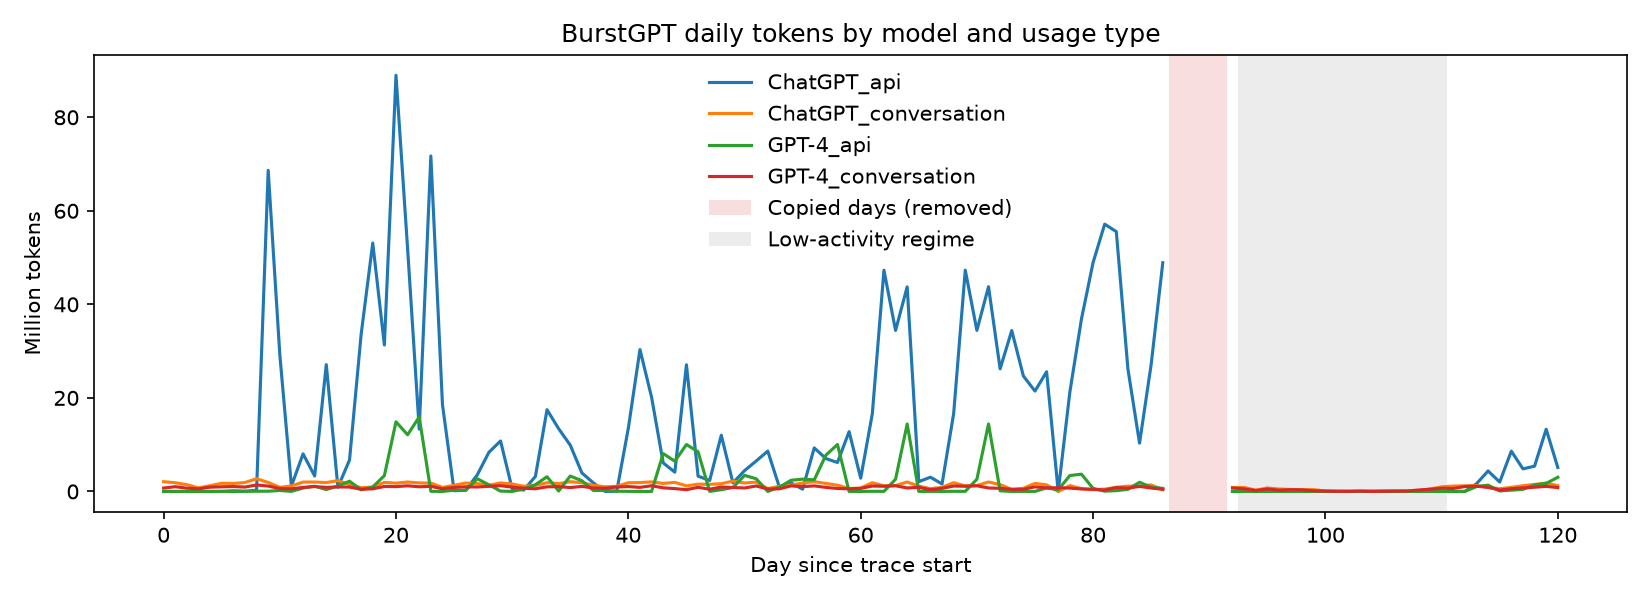

burstgpt_hour_day_heatmap


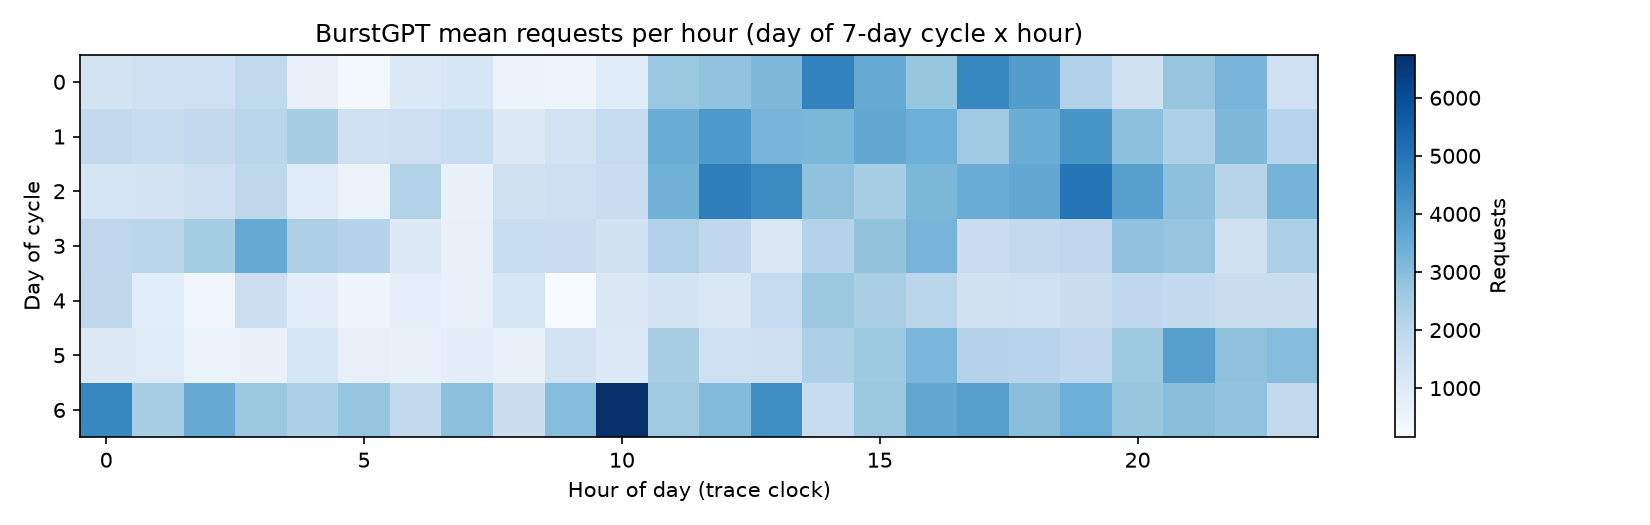

wildchat_weekly


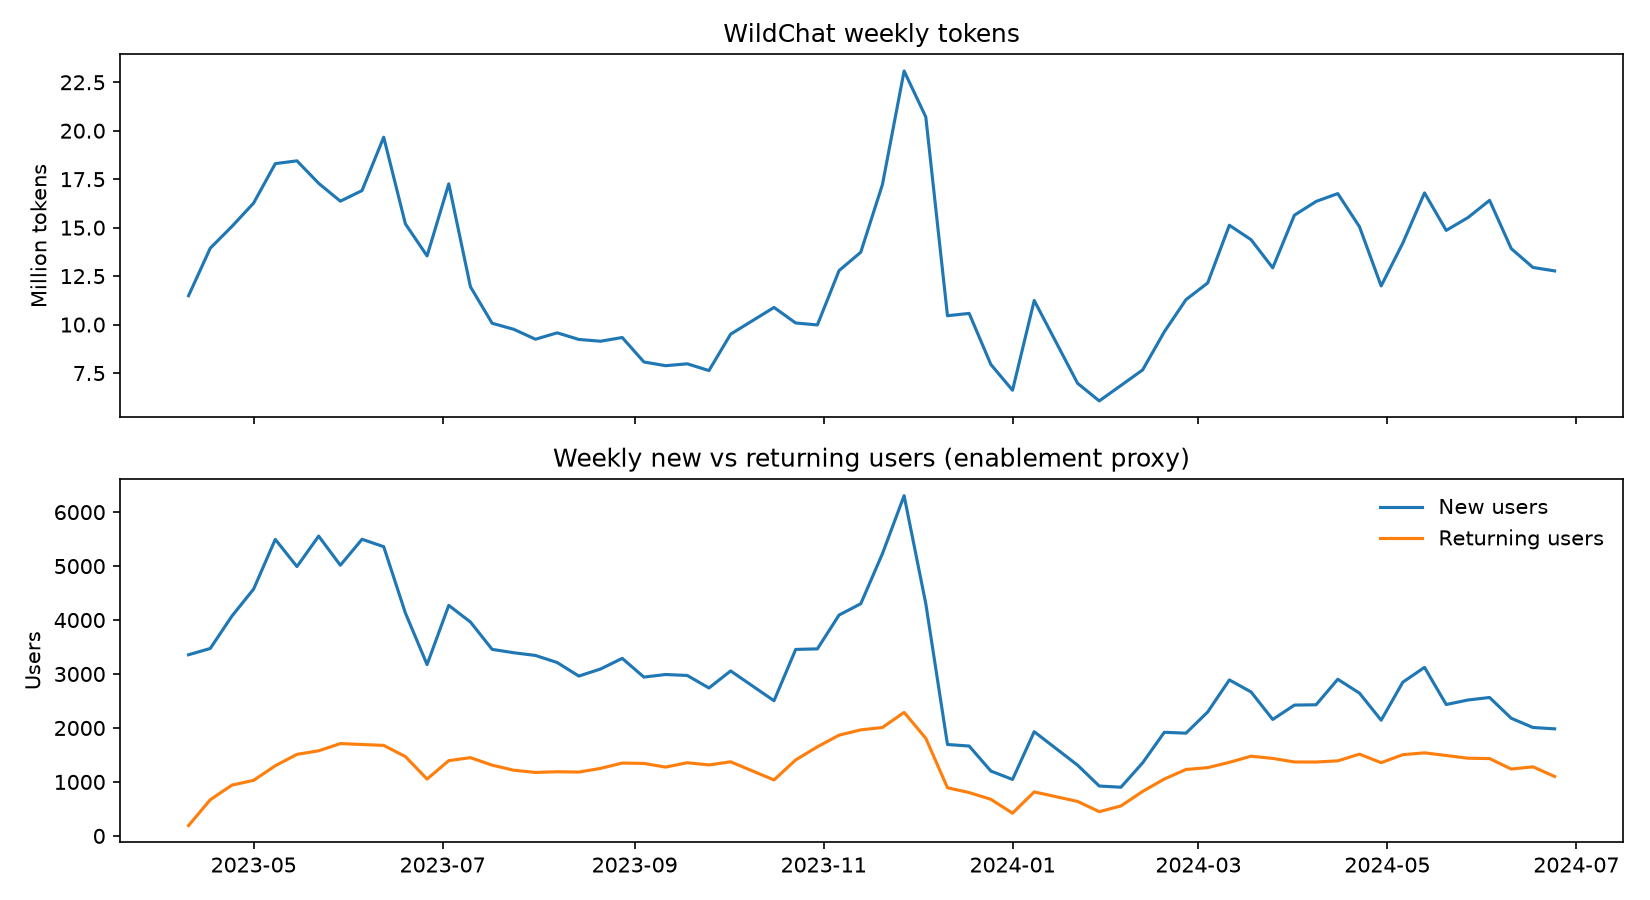

In [9]:
with step("preprocessing figures"):
    figs = sorted(Path("reports/figures").glob("*.png"))
    if not figs:
        print("No preprocessing figures in this bundle; skipped.")
    for f in figs:
        print(f.stem)
        show_img(f, width=800)

# Part B: Phase 1, exploration and baselines

## B1. The series
First we simply look at each series. Shaded areas are flagged days (copied, low activity, outage);
the dashed line marks the start of the **hold-out**, the final stretch we keep aside for a last, fair test.
The table below gives the size and variability: the **coefficient of variation** (CV = standard
deviation / mean) says how bursty a series is (above 1 is very bursty).

,driver,unit,n,mean,std,cv,zero_share,skewness
0,burst_tokens_total_daily,tokens per day,87,2.185054e+07,2.118812e+07,0.970,0.000,1.415
1,burst_tokens_api_daily,tokens per day,87,1.957142e+07,2.122671e+07,1.085,0.000,1.395
2,burst_tokens_chat_daily,tokens per day,87,2.279112e+06,7.205549e+05,0.316,0.000,-0.399
3,burst_requests_hourly,requests per hour,2088,2.193864e+03,3.728942e+03,1.700,0.021,2.821
4,wildchat_conversations_daily,conversations per day,121,2.213041e+03,7.051700e+02,0.319,0.000,2.620
5,eci_wages_quarterly,index,103,1.256470e+02,2.462100e+01,0.196,0.000,0.506
6,ppi_hosting_monthly,index,311,1.088180e+02,6.685000e+00,0.061,0.000,0.971


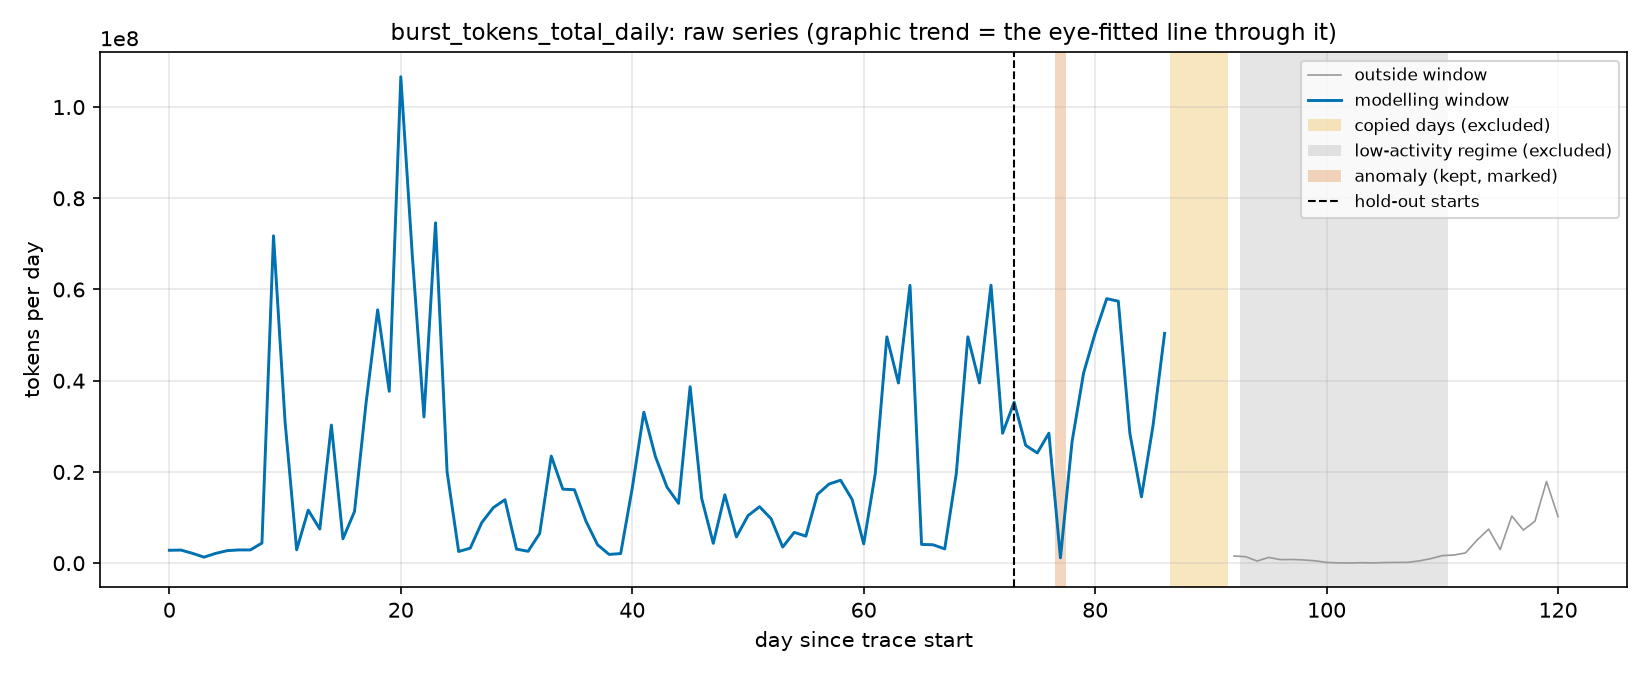

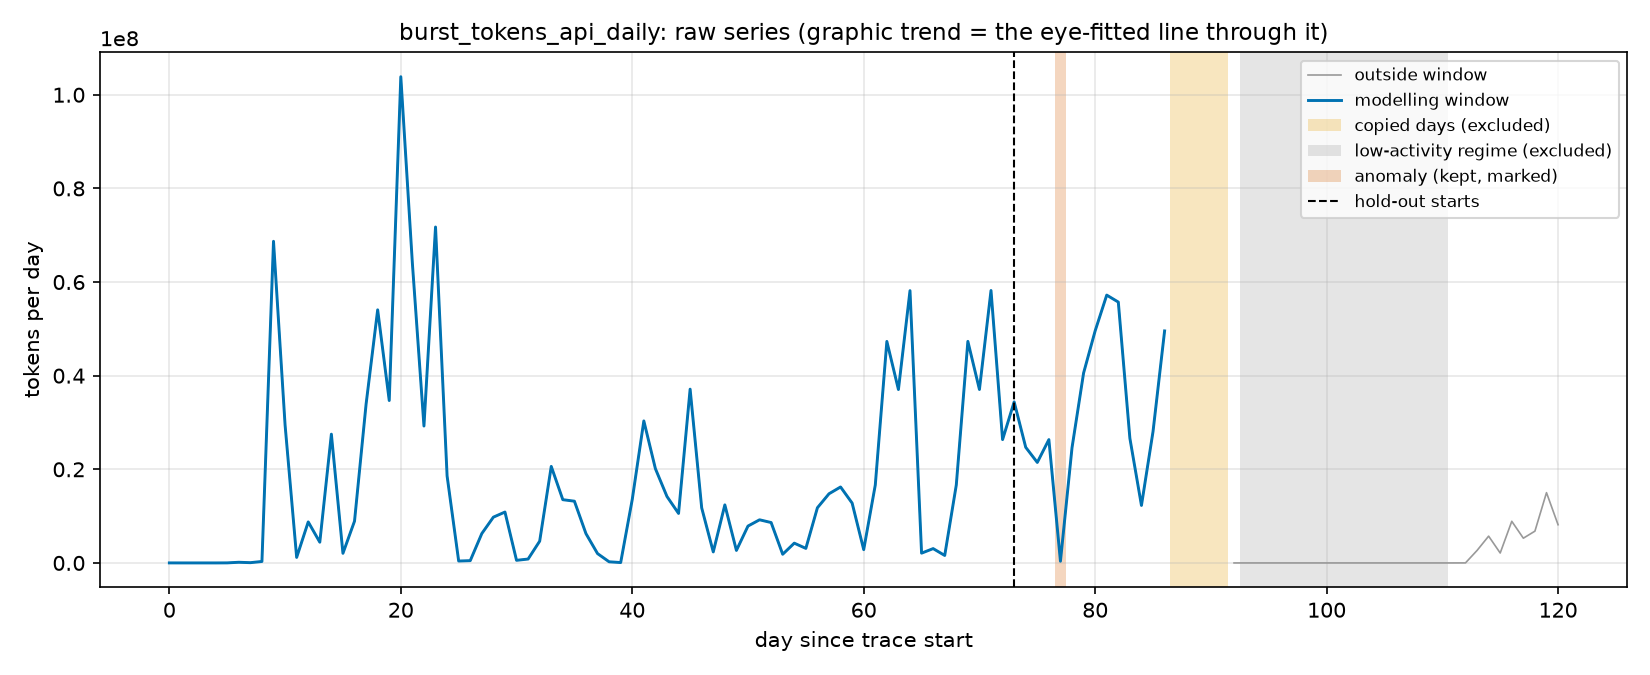

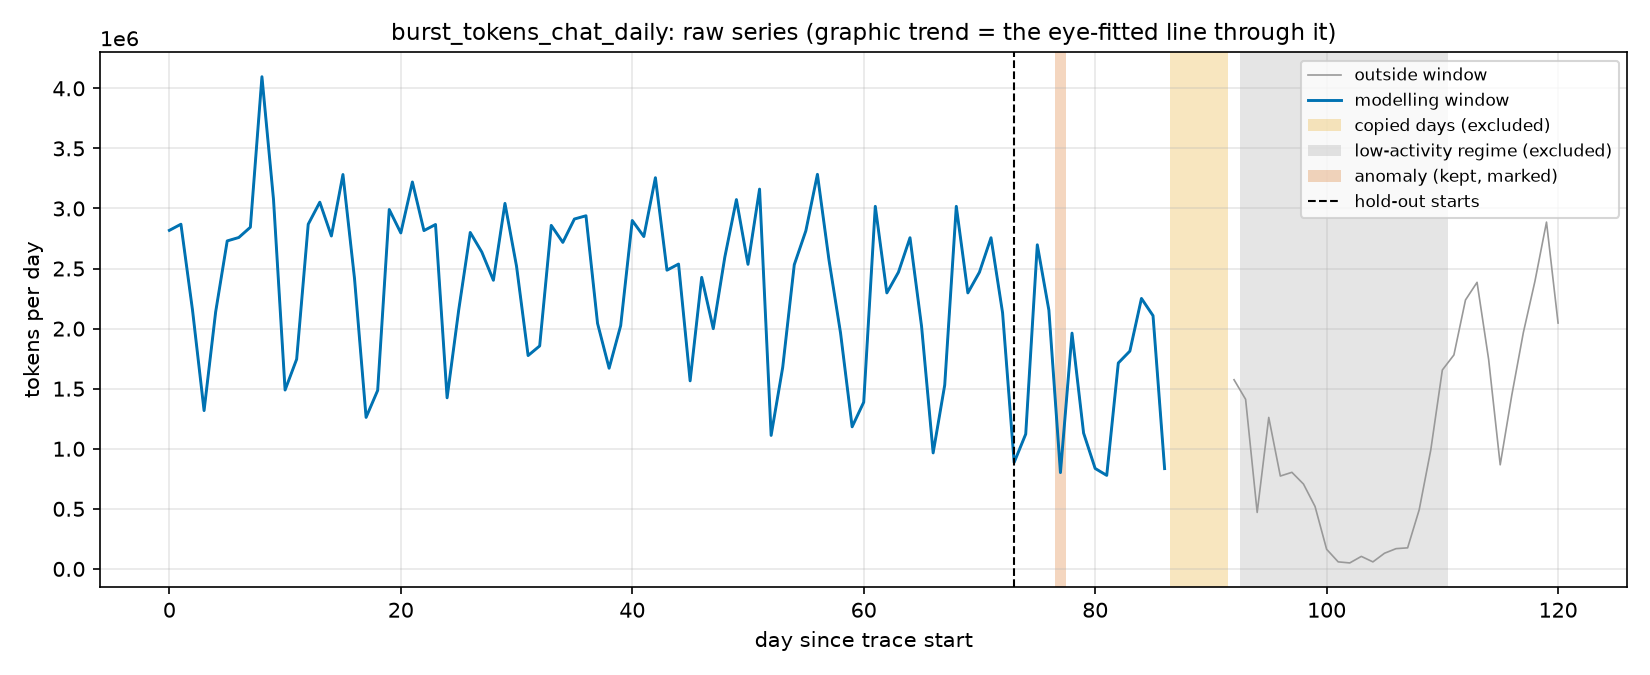

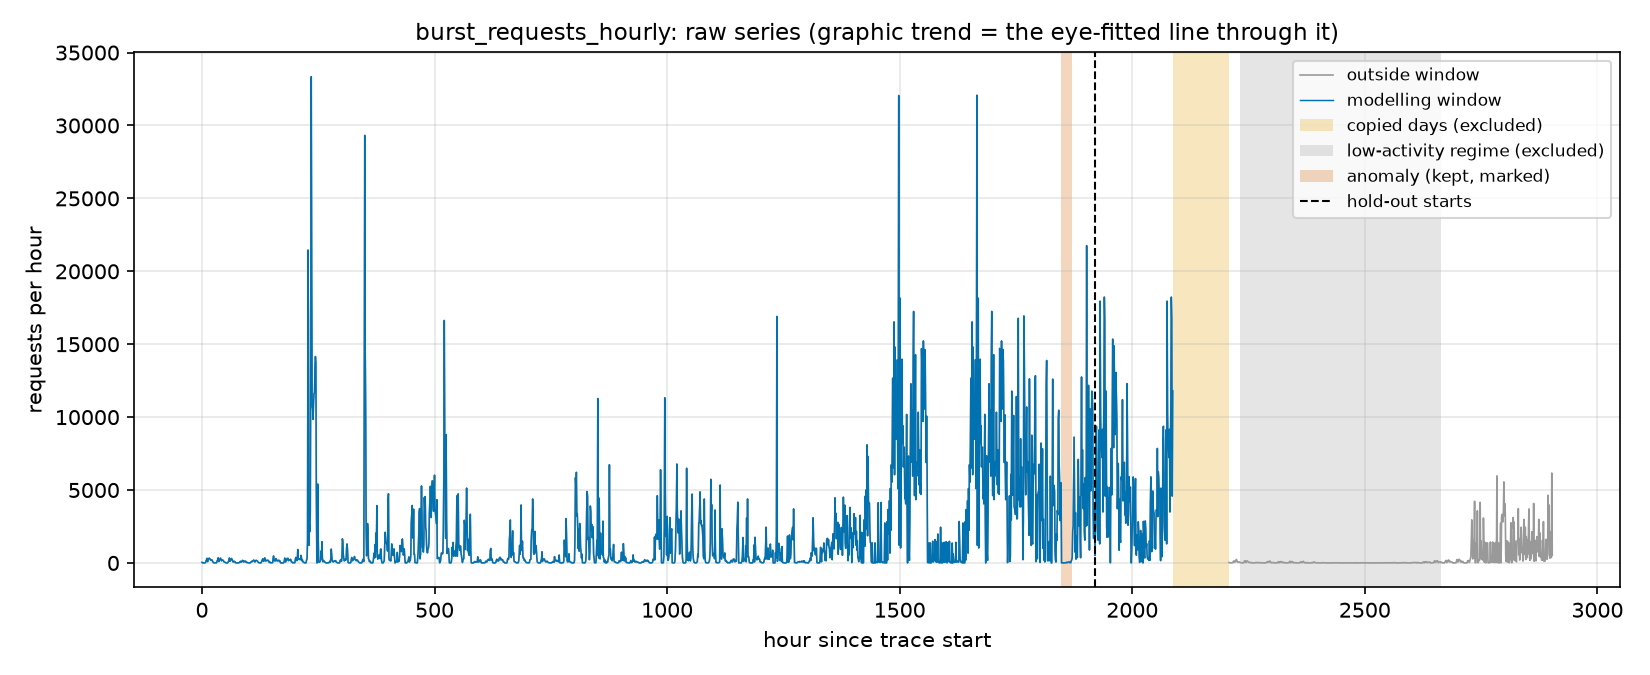

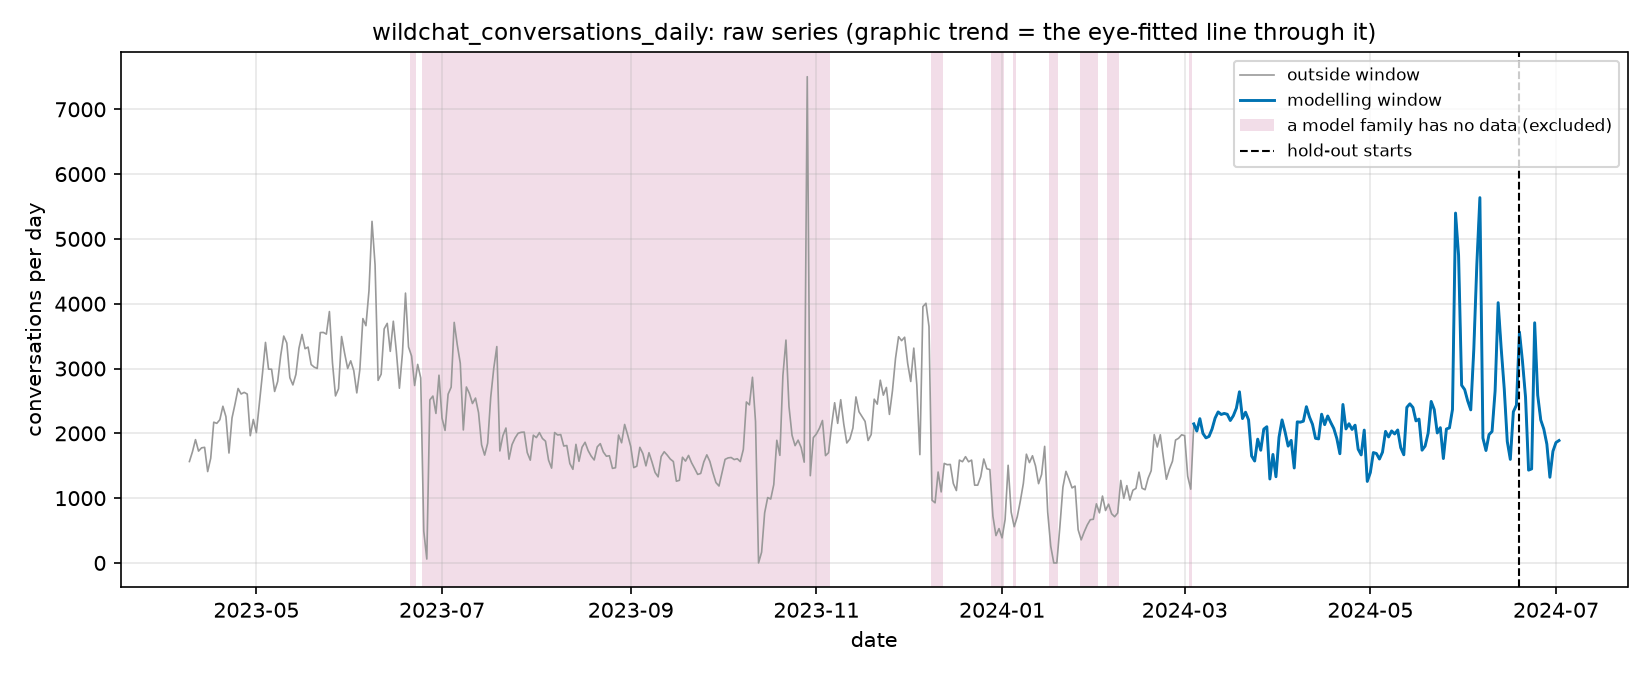

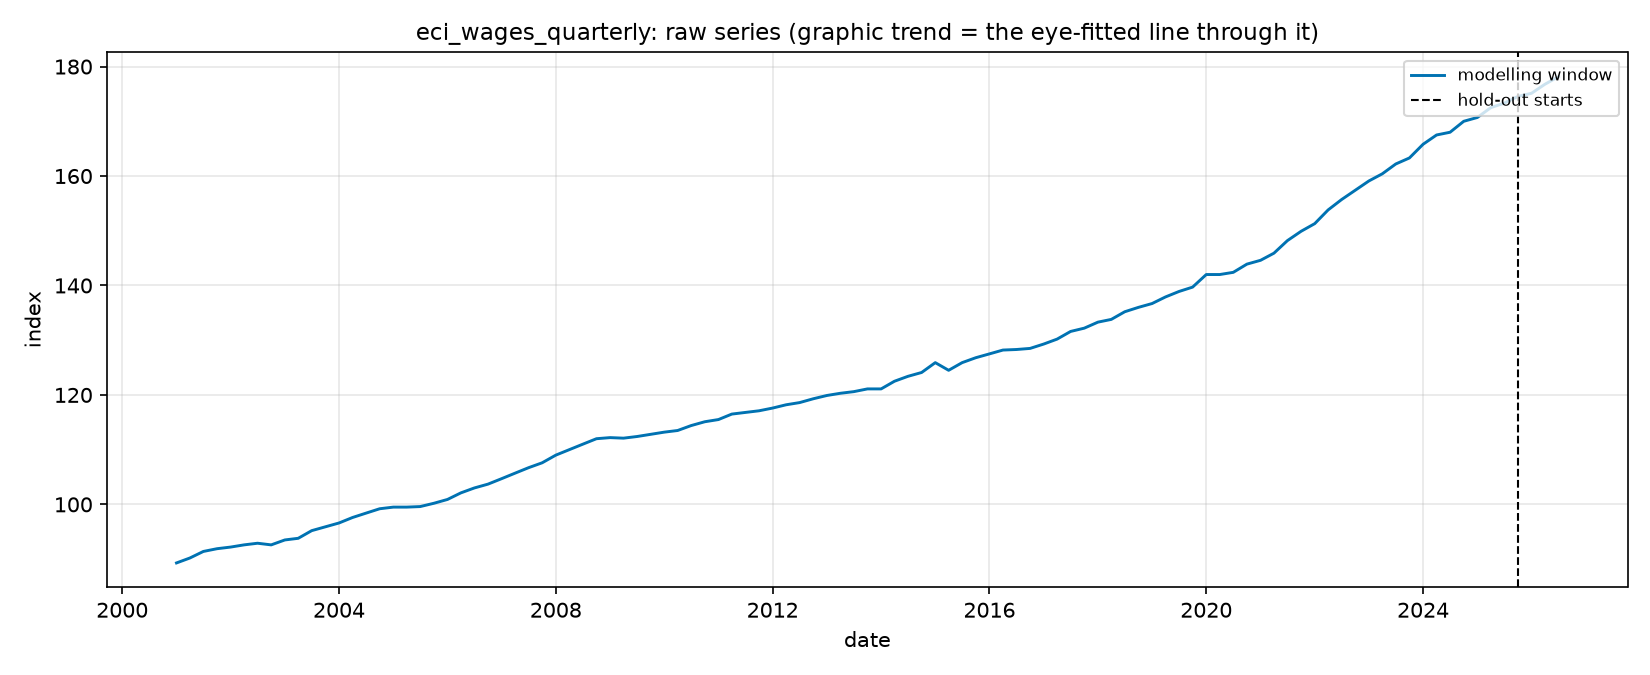

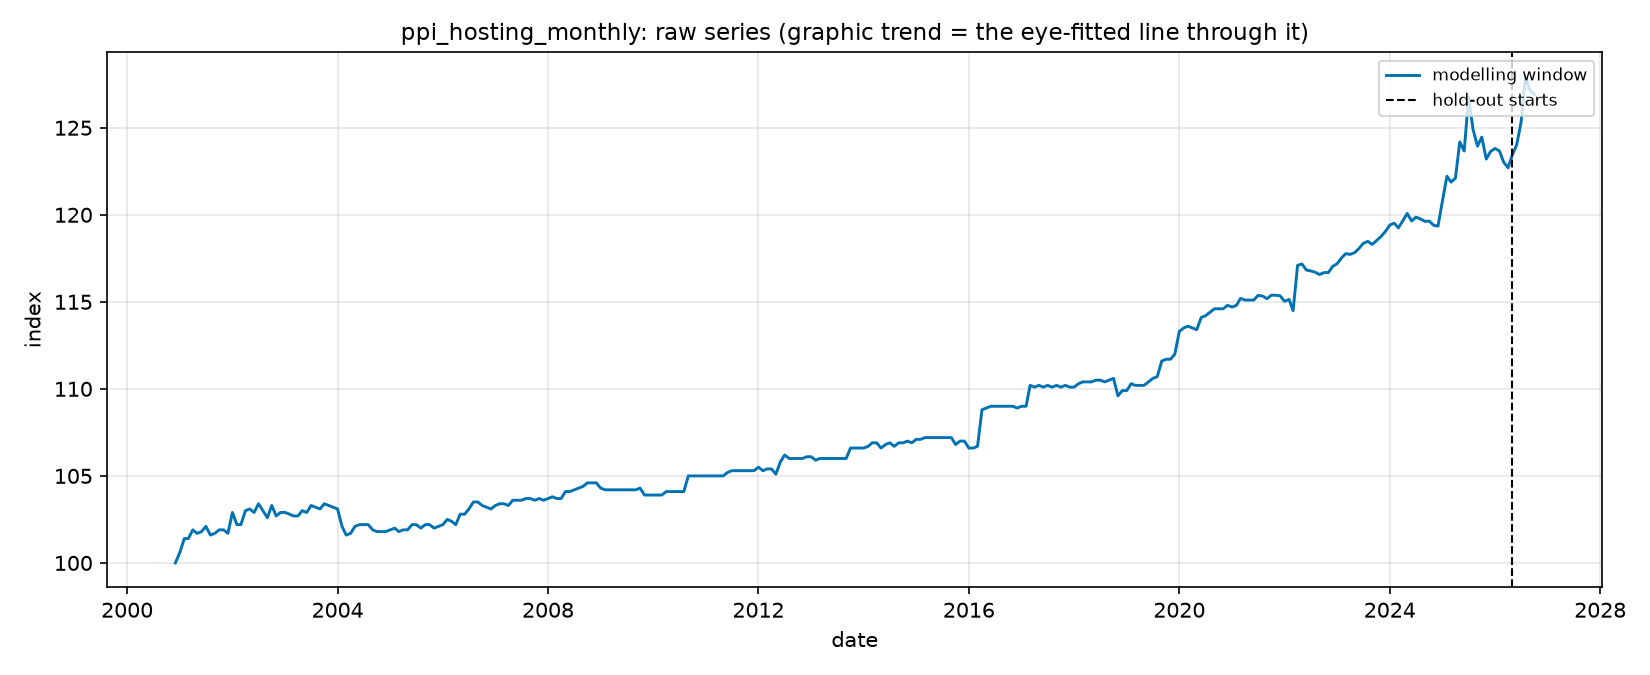

In [10]:
with step("series"):
    show_table(read_table("phase1", "summary_stats"), n=20,
               cols=["driver", "unit", "n", "mean", "std", "cv", "zero_share", "skewness"])
    for name in NAMES:
        show_img(f"outputs/phase1/figures/{name}_series.png", width=850)

## B2. Components: trend, seasonality and remainder
A series = trend + seasonal pattern + remainder (**additive**), or trend x seasonal x remainder
(**multiplicative**, when the swings grow with the level). Our rule: if the rolling standard deviation
rises with the rolling mean (correlation above 0.5), choose multiplicative. **Strength** (0 to 1) says
how much of the variation the trend or the seasonal part explains.

,driver,type,reason,method,seasonal_strength,trend_strength
0,burst_tokens_total_daily,multiplicative,rolling std rises with rolling mean (corr 0.75 > 0.5),STL (robust),0.127,0.368
1,burst_tokens_api_daily,multiplicative,rolling std rises with rolling mean (corr 0.75 > 0.5),STL (robust),0.057,0.683
2,burst_tokens_chat_daily,additive,rolling std does not track rolling mean (corr -0.00 <= 0.5),STL (robust),0.723,0.505
3,burst_requests_hourly,additive,"series has zero or negative values, so multiplicative is not possible","MSTL(24, 168)",0.366,0.384
4,wildchat_conversations_daily,multiplicative,rolling std rises with rolling mean (corr 0.84 > 0.5),STL (robust),0.511,0.491
5,eci_wages_quarterly,multiplicative,rolling std rises with rolling mean (corr 0.67 > 0.5),STL (robust),0.000,1.000
6,ppi_hosting_monthly,multiplicative,rolling std rises with rolling mean (corr 0.63 > 0.5),STL (robust),0.076,0.993


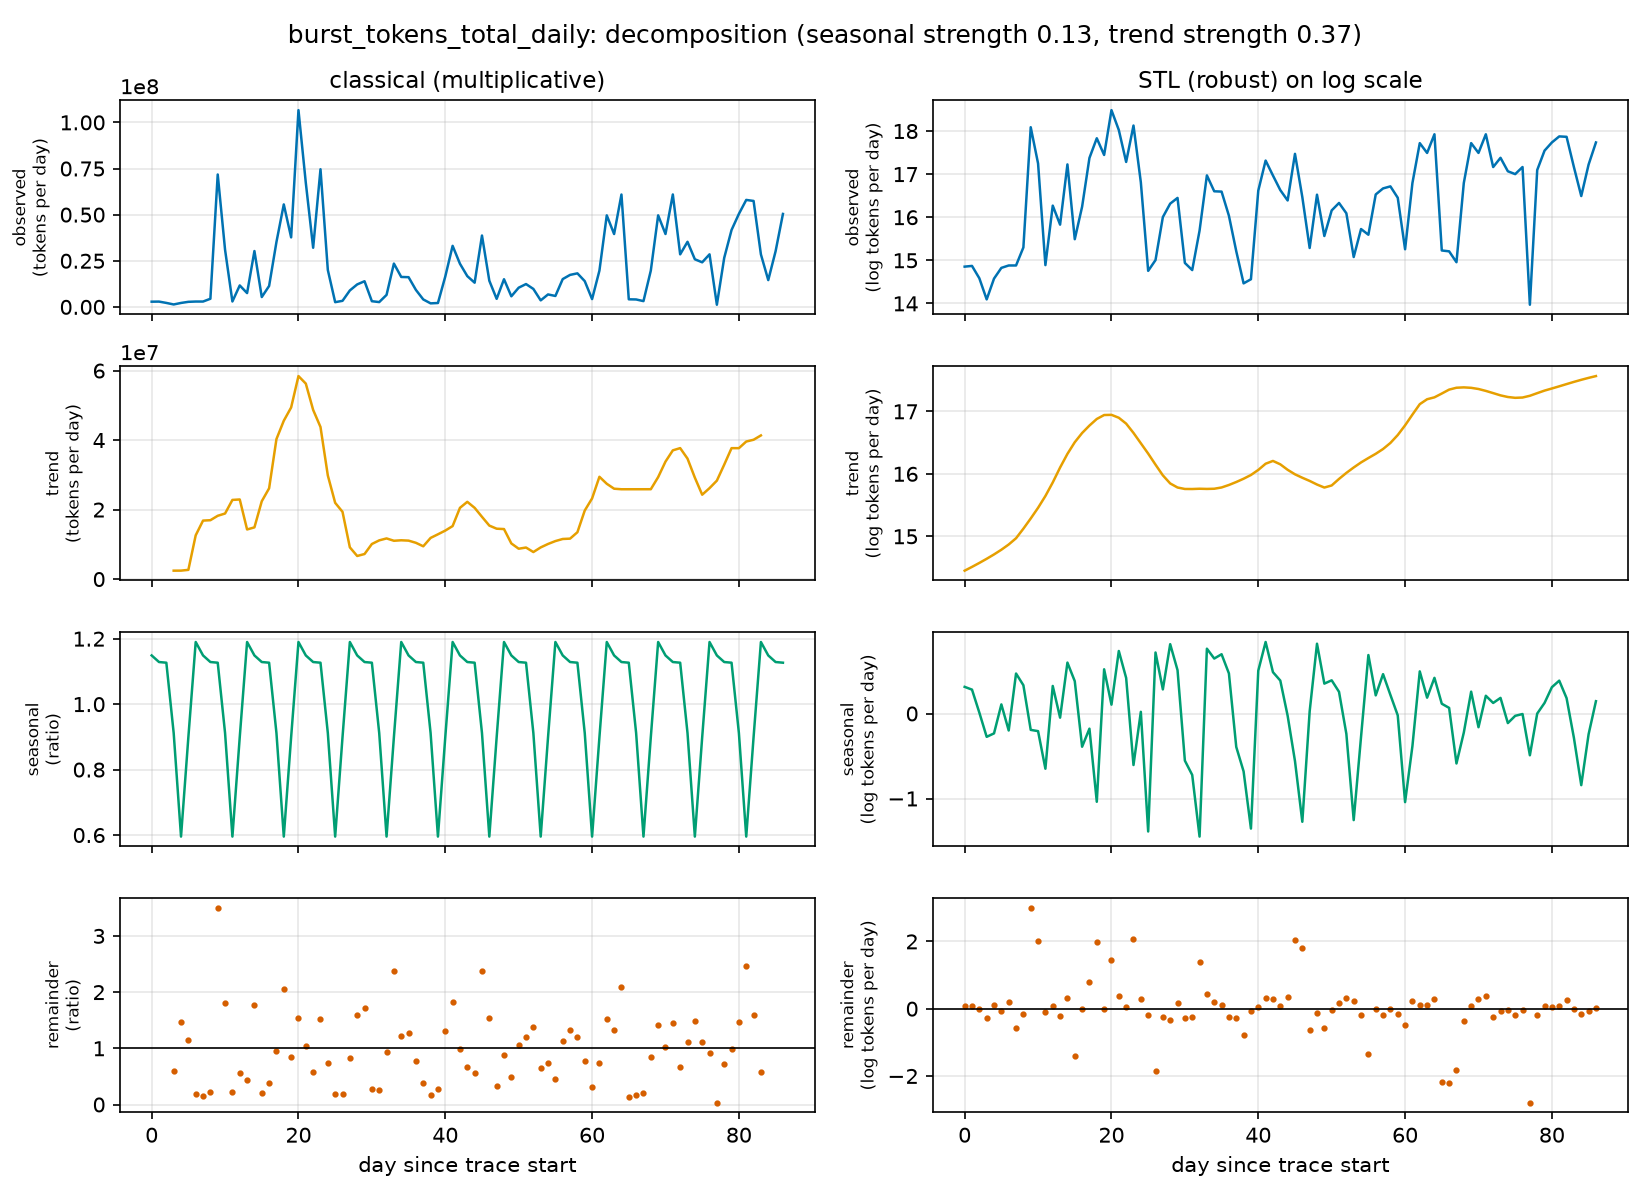

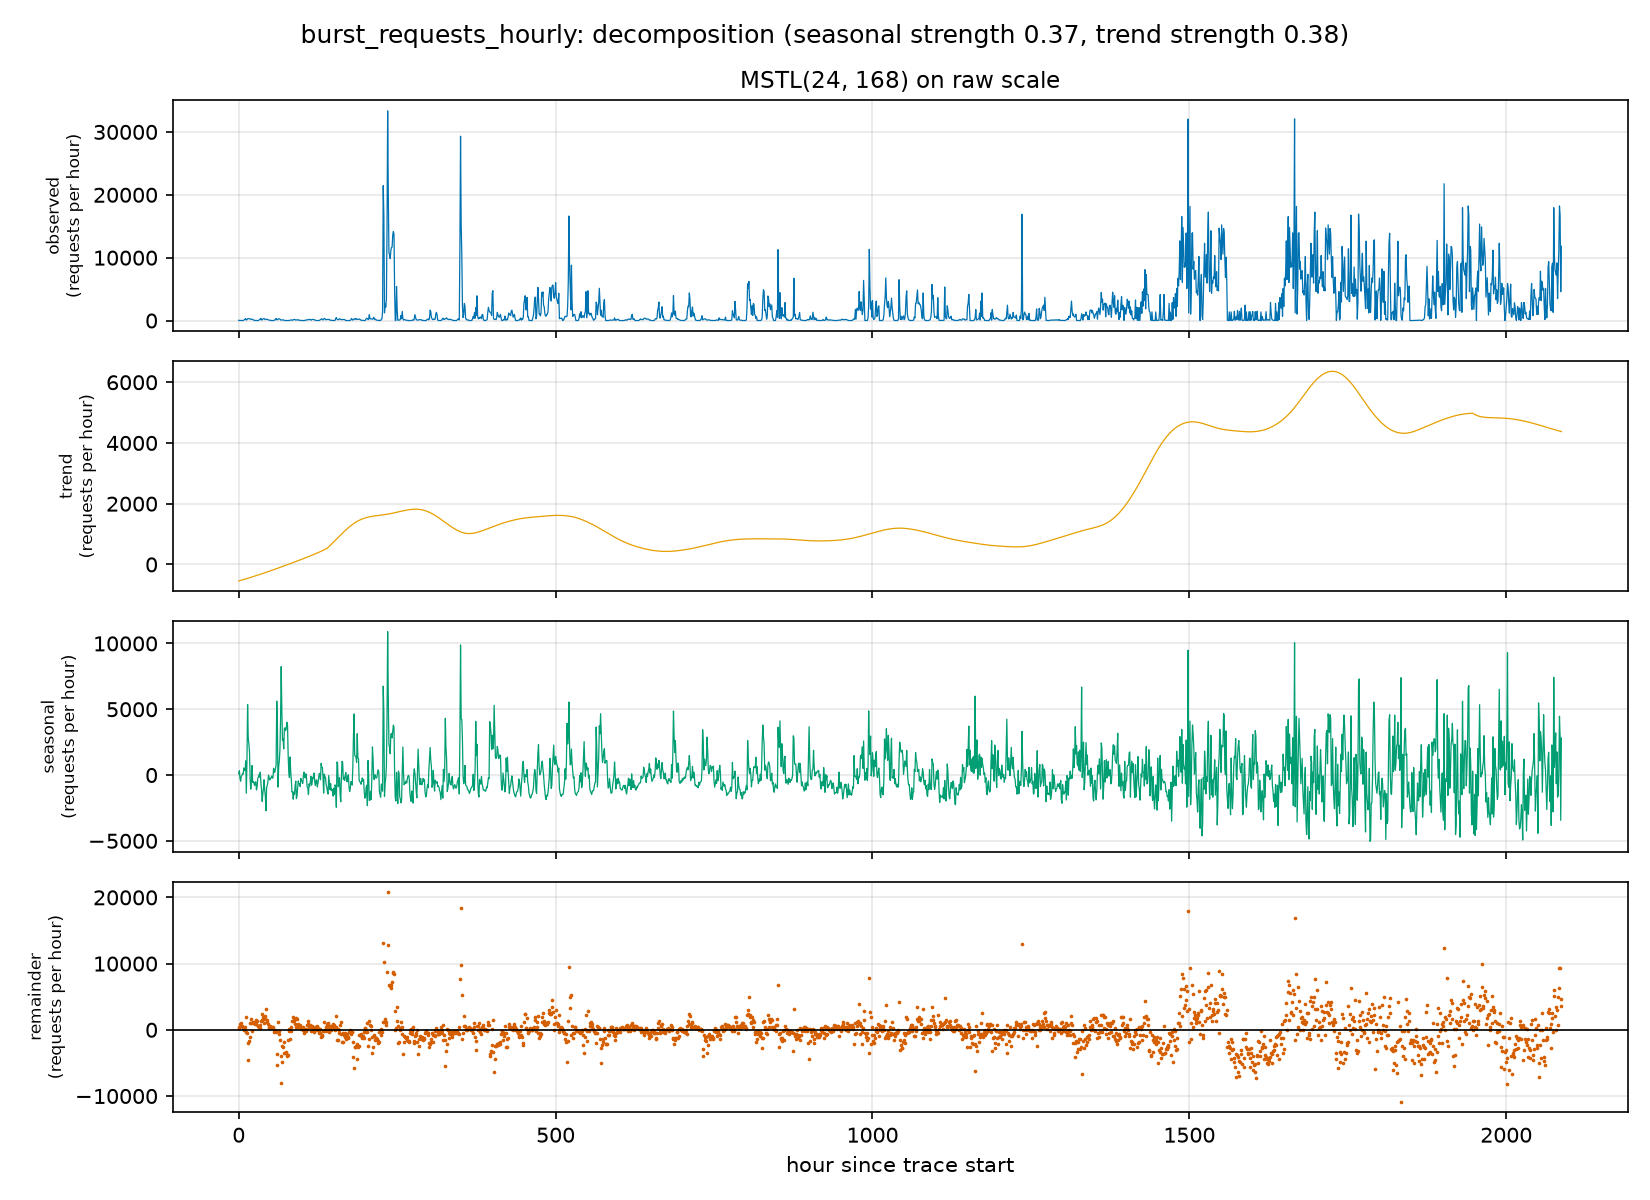

In [11]:
with step("decomposition"):
    show_table(read_table("phase1", "decomposition"), n=20,
               cols=["driver", "type", "reason", "method", "seasonal_strength", "trend_strength"])
    for name in ["burst_tokens_total_daily", "burst_requests_hourly"]:
        show_img(f"outputs/phase1/figures/{name}_decomposition.png", width=850)

## B3. Measuring the trend: four classic methods
On BurstGPT total tokens per day we measure the trend four ways: **semi-averages** (mean of the second
half minus mean of the first half, divided by the distance between their centres), a **centred moving
average**, and **least squares** with a straight line and with a quadratic curve. The slope is in tokens
per day and as a percentage of the mean.

,method,slope_per_step,slope_pct_of_mean,how
0,semi_averages,124918.966,0.572,difference of the two half means / distance between their centres
1,centred_moving_average,140803.756,0.644,least squares slope of the 7-point centred MA
2,least_squares_linear,193462.145,0.885,b in y = a + b t
3,least_squares_quadratic,647357.123,2.963,"slope b + 2ct at the end of the window (t=86), c=5278; at the middle it equals the lin..."


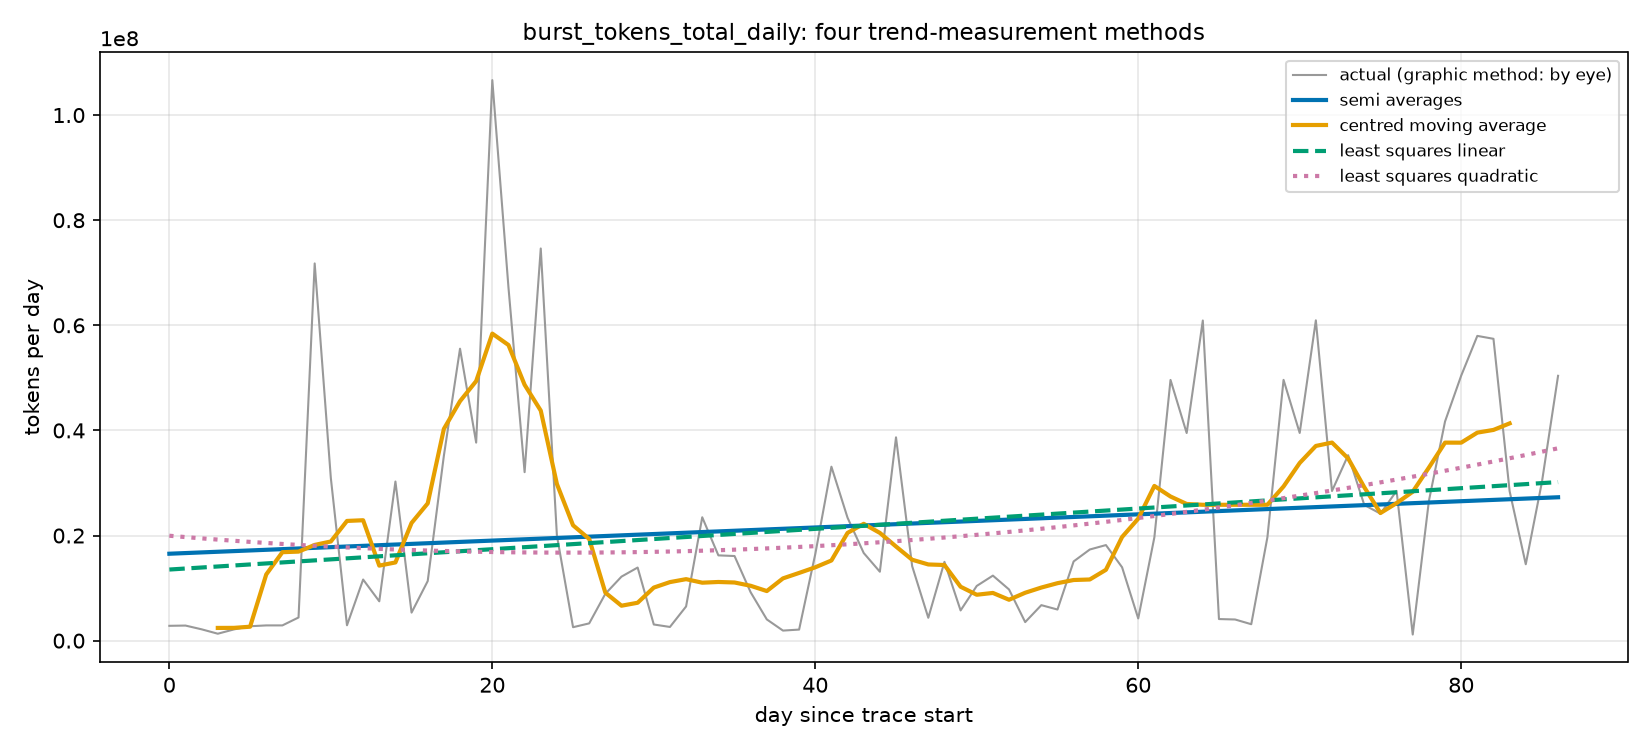

In [12]:
with step("trend methods"):
    show_table(read_table("phase1", "trend_methods"), cols=["method", "slope_per_step", "slope_pct_of_mean", "how"])
    show_img("outputs/phase1/figures/trend_methods_burstgpt.png", width=850)

## B4. Dependence: ACF and PACF
The **ACF** shows how a value correlates with the value k steps earlier; the **PACF** shows the same after
removing the effect of the steps in between. Bars outside the shaded band are significant. A spike at
lag 7 in daily data means a weekly pattern; a slowly decaying ACF means a trend (not stationary).

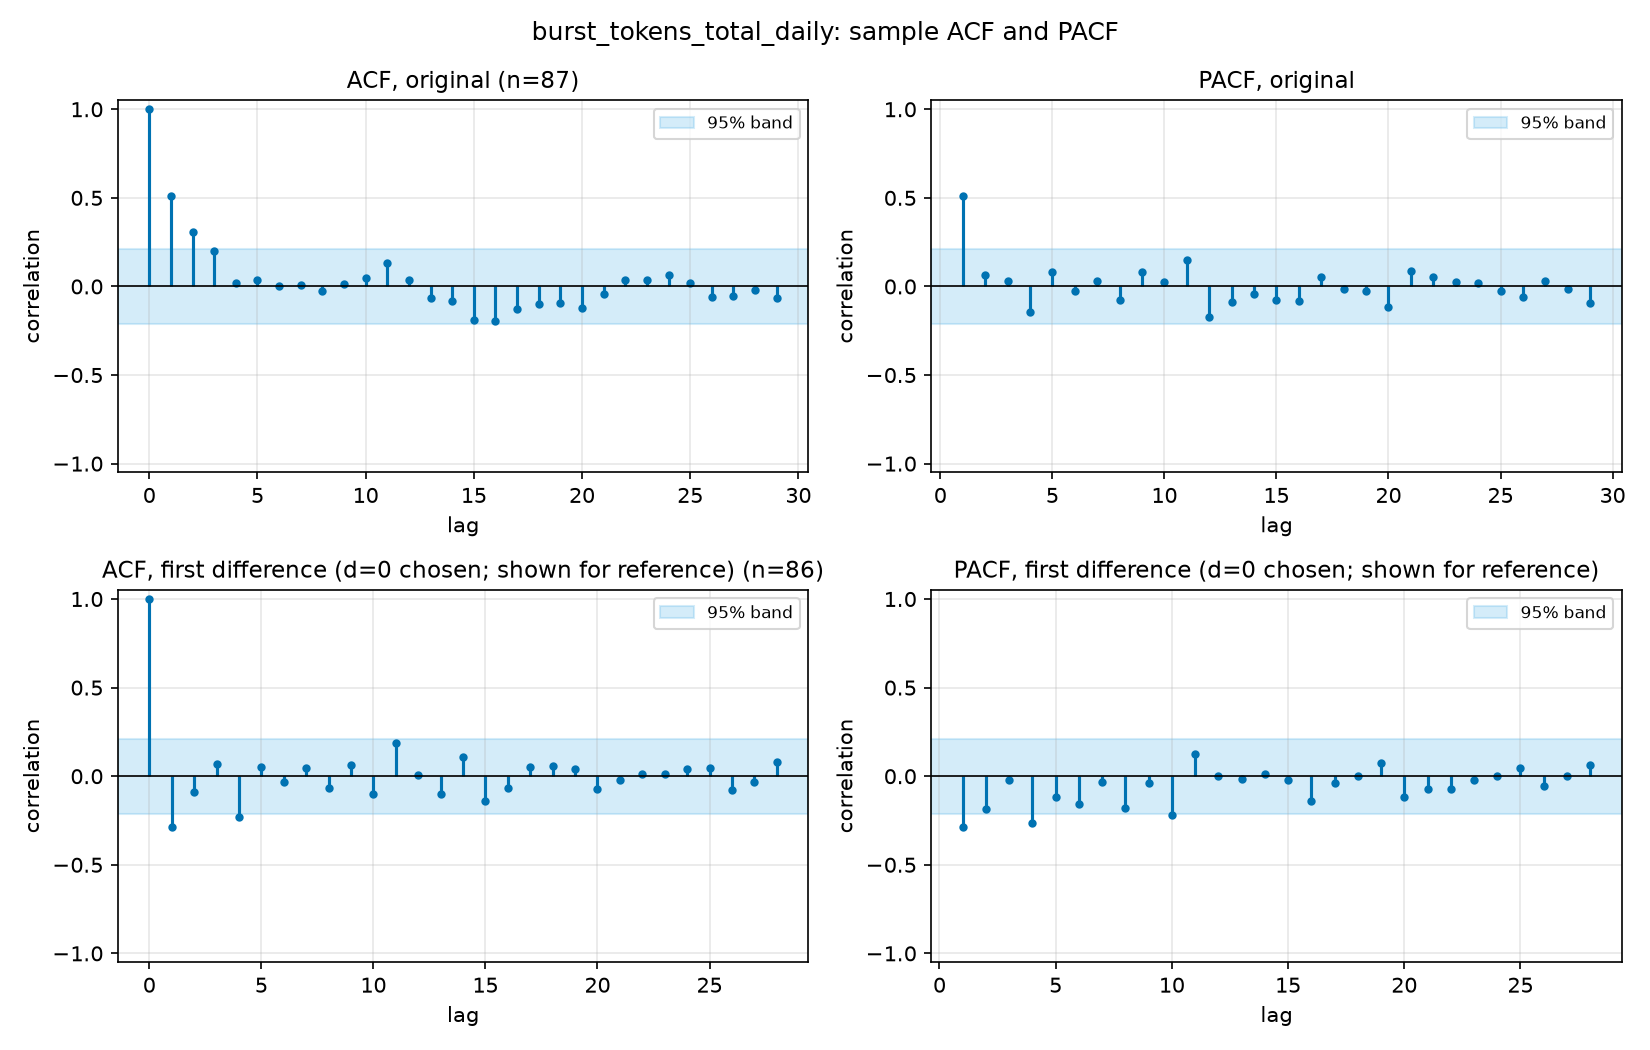

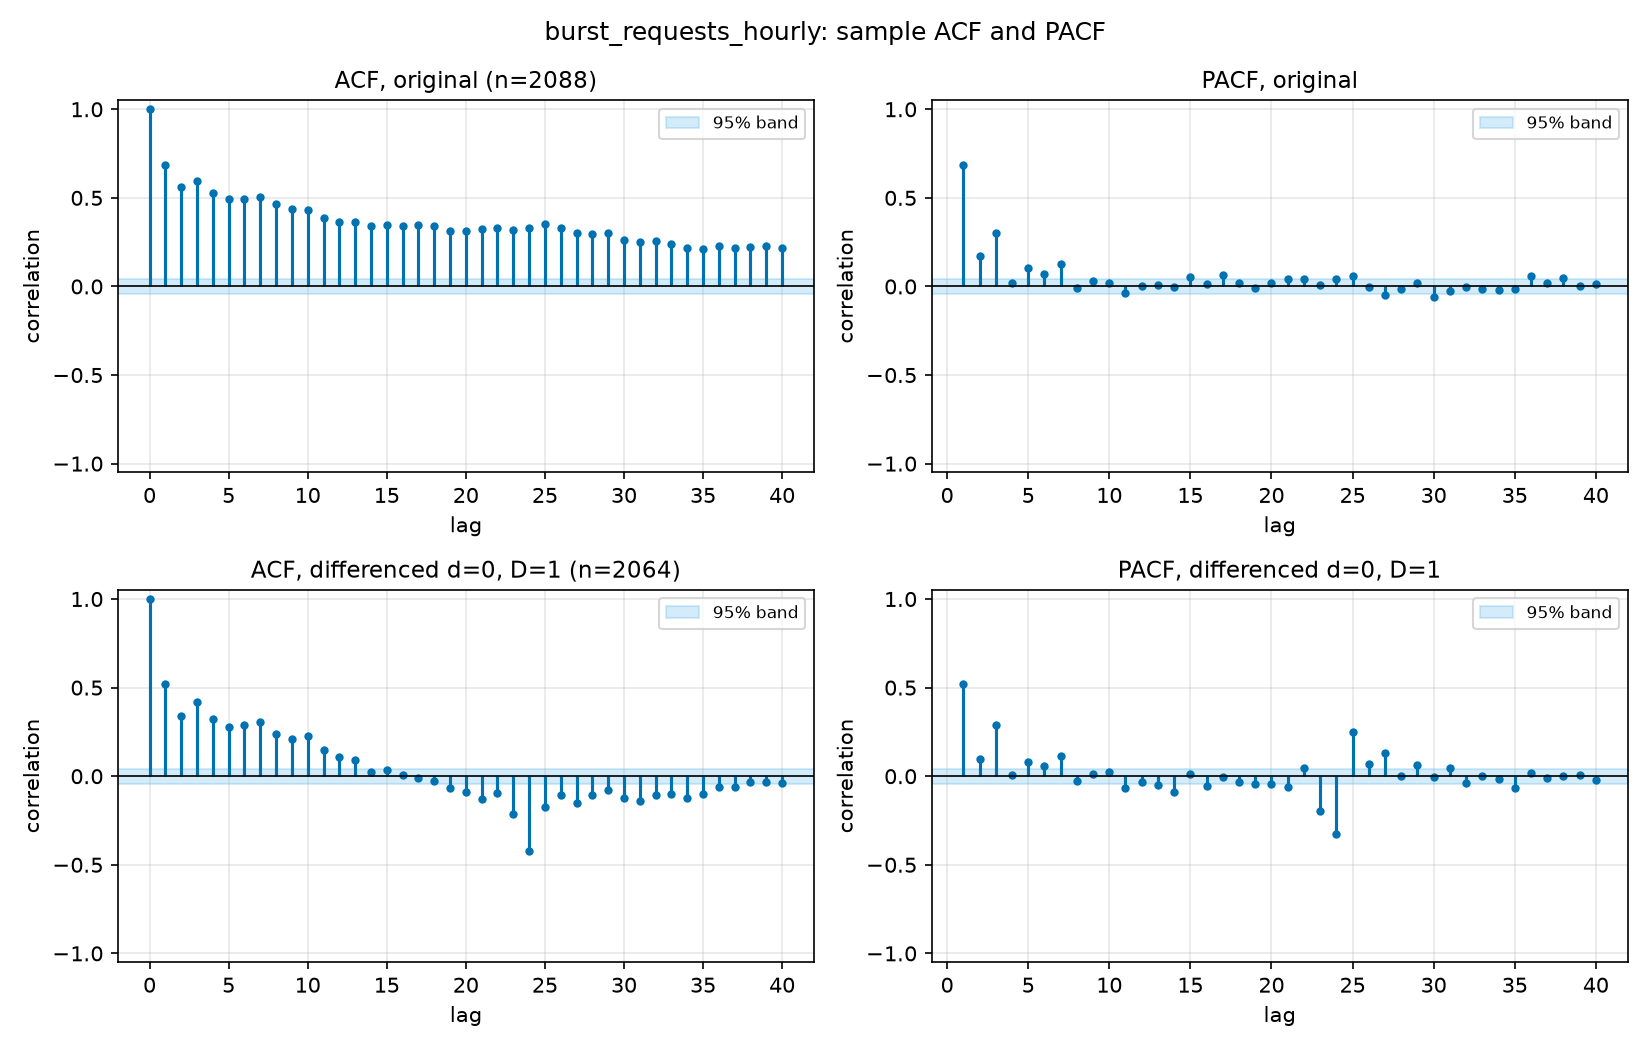

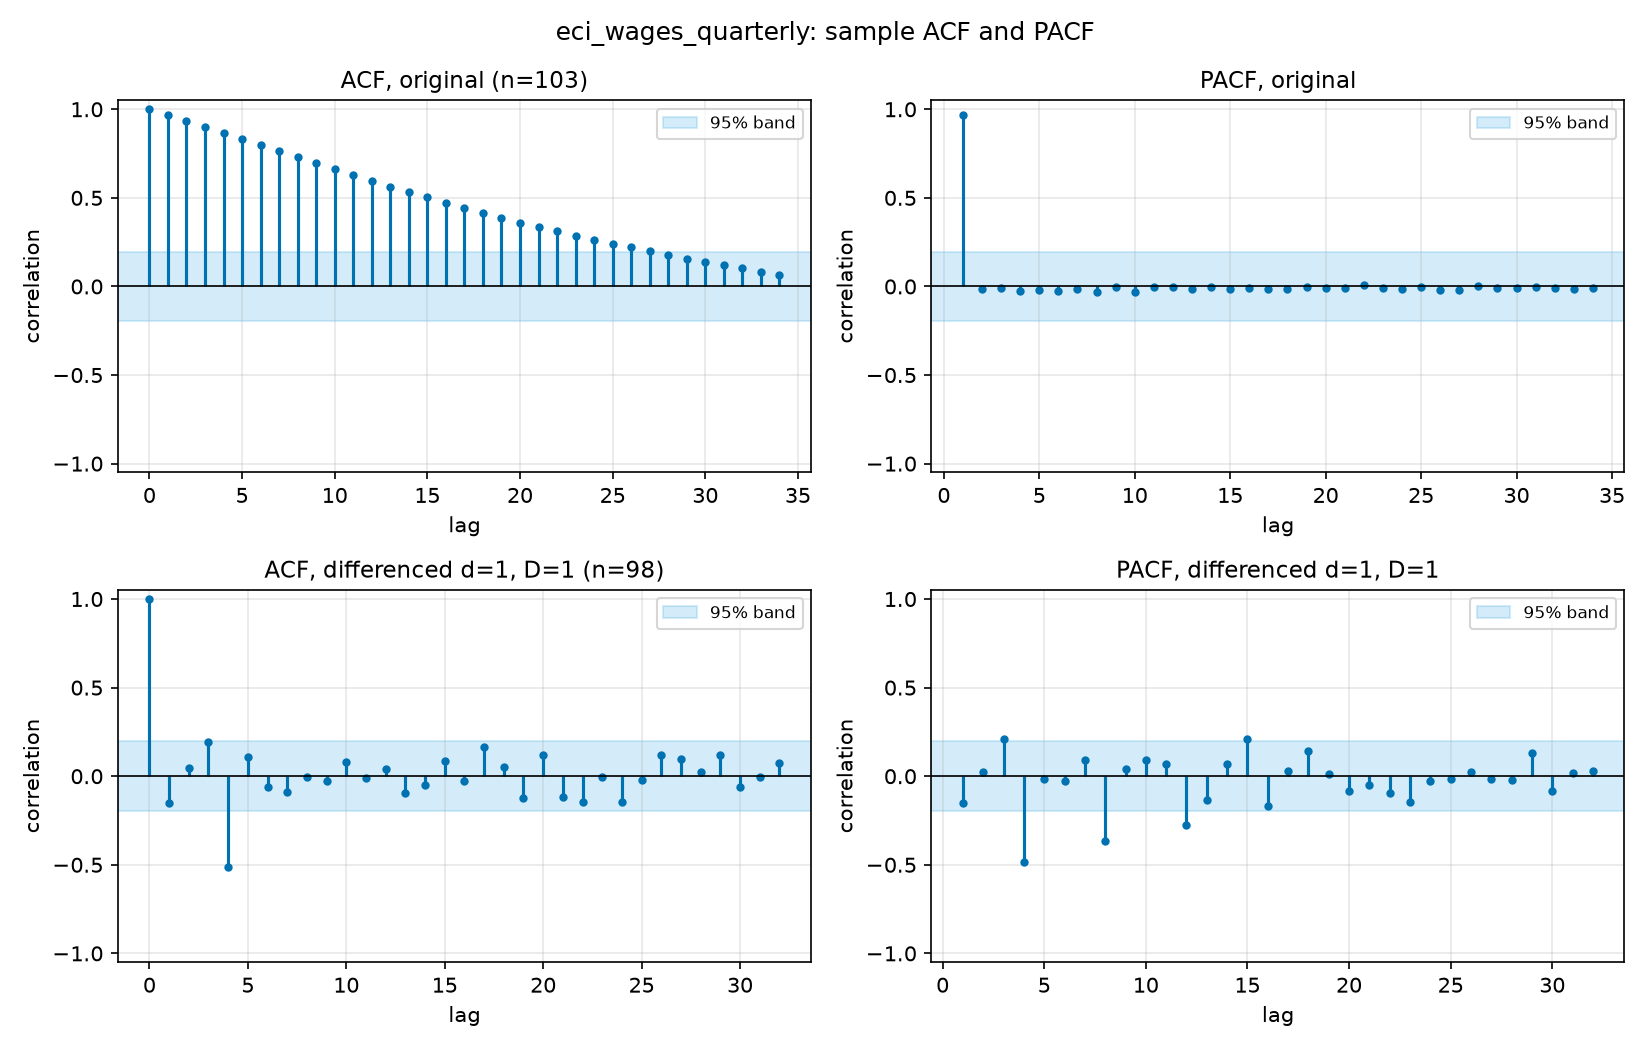

In [13]:
with step("acf pacf"):
    for name in ["burst_tokens_total_daily", "burst_requests_hourly", "eci_wages_quarterly"]:
        show_img(f"outputs/phase1/figures/{name}_acf_pacf.png", width=850)

## B5. Stationarity: ADF and KPSS together
ARIMA needs a **stationary** series (constant mean and variance). The two tests ask opposite questions:
**ADF**: "is there a unit root?" (small p-value = stationary); **KPSS**: "is it stationary?"
(small p-value = not stationary). We difference (d = ordinary, D = seasonal) until both agree the
series is stationary. The decision per driver is carried into Phase 2.

In [14]:
with step("stationarity"):
    show_table(read_table("phase1", "stationarity"), n=25,
               cols=["driver", "d", "D", "adf_stat", "adf_p", "kpss_stat", "kpss_p", "verdict"])
    dec = pd.DataFrame([{k: d[k] for k in ("name", "d", "D", "decomposition", "tests_agree")} for d in HANDOFF["drivers"]])
    print("Decision carried into Phase 2:")
    show_table(dec, n=20)

,driver,d,D,adf_stat,adf_p,kpss_stat,kpss_p,verdict
0,burst_tokens_total_daily,0,0,-5.093,0.000,0.251,0.100,stationary [KPSS p-value at the table bound]
1,burst_tokens_total_daily,0,1,-3.088,0.027,0.070,0.100,stationary [KPSS p-value at the table bound]
2,burst_tokens_total_daily,1,0,-6.618,0.000,0.086,0.100,stationary [KPSS p-value at the table bound]
3,burst_tokens_total_daily,1,1,-5.703,0.000,0.097,0.100,stationary [KPSS p-value at the table bound]
4,burst_tokens_total_daily,2,0,-5.767,0.000,0.157,0.100,stationary [KPSS p-value at the table bound]
5,burst_tokens_api_daily,0,0,-5.069,0.000,0.271,0.100,stationary [KPSS p-value at the table bound]
6,burst_tokens_api_daily,0,1,-3.064,0.029,0.071,0.100,stationary [KPSS p-value at the table bound]
7,burst_tokens_api_daily,1,0,-6.560,0.000,0.086,0.100,stationary [KPSS p-value at the table bound]
8,burst_tokens_api_daily,1,1,-5.689,0.000,0.097,0.100,stationary [KPSS p-value at the table bound]
9,burst_tokens_api_daily,2,0,-5.828,0.000,0.160,0.100,stationary [KPSS p-value at the table bound]


Decision carried into Phase 2:


,name,d,D,decomposition,tests_agree
0,burst_tokens_total_daily,0,0,multiplicative,True
1,burst_tokens_api_daily,0,0,multiplicative,True
2,burst_tokens_chat_daily,0,1,additive,True
3,burst_requests_hourly,0,1,additive,True
4,wildchat_conversations_daily,0,1,multiplicative,True
5,eci_wages_quarterly,1,1,multiplicative,True
6,ppi_hosting_monthly,1,1,multiplicative,True


## B6. Anomaly screen and the day-77 check
We flag a day when its **robust z-score** (distance from the median, measured in MADs, the median
absolute deviation) is above 3.5. The known outage on day 77 is the test case. The result is shown
honestly below, straight from `PHASE1_SUMMARY.md`, including a FAIL if that is what happened.

In [15]:
with step("day 77"):
    an = read_table("phase1", "anomalies")
    show_table(an[an["note"].fillna("").str.contains("day-77")], cols=["driver", "time", "robust_z", "note"])
    text = md_section("outputs/phase1/PHASE1_SUMMARY.md", "day-77")
    display(Markdown(text) if text else Markdown("_No day-77 section in the summary._"))

,driver,time,robust_z,note
0,burst_tokens_total_daily,77,3.158,"day-77 check: FAIL (day 77 not flagged; |robust z| = 3.16 vs threshold 3.5, rank 1 of ..."


Result: **FAIL (day 77 not flagged; |robust z| = 3.16 vs threshold 3.5, rank 1 of 80 days, log scale)**. Day 77 is a one-day outage that preprocessing already marks as `anomaly_low_day` (kept in the series and shaded on every plot). The Phase 1 screen (robust z-score of the seasonal-naive residual, log scale, threshold 3.5) gives day 77 |z| = 3.16, rank 1 of 80 scored days. Most extreme days: day 77 (|z| 3.16), day 30 (|z| 2.88), day 25 (|z| 2.79).

Why it is a finding, not a bug: the screen flags 0 day(s) in total on this series, because the median absolute deviation of the residual is inflated by the bursty API segment (its coefficient of variation is in section 2), so a genuine one-day outage does not stand out from ordinary week-on-week swings. For comparison, the same robust z on the STL remainder (log scale) gives day 77 |z| = 8.18 but flags 15 of 87 days (17%), which is too many to be a useful screen. The threshold was not tuned to force a PASS. Practical consequence: known outages must come from the preprocessing flags, not from a residual screen, and Phase 2 models of BurstGPT tokens should use robust fitting or an outage dummy for day 77.

## B7. Baselines: the bar every later model must beat
Five simple forecasts: **naive** (repeat the last value), **seasonal naive** (repeat the last season),
**mean**, **drift** (straight line from first to last value) and a **seasonal moving average**.
We score them with **MASE**: the forecast error divided by the error of the seasonal naive forecast
on the training data, so **MASE below 1 means better than seasonal naive**.
**Every later model must beat the seasonal naive baseline.**

,rank,driver,best_baseline,cv_mase,holdout_mase,seasonal_naive_cv_mase,n_folds
0,1,burst_tokens_api_daily,mean,0.495,0.909,0.530,4
1,2,burst_tokens_total_daily,mean,0.503,0.873,0.529,4
2,3,eci_wages_quarterly,drift,0.529,0.200,1.737,17
3,4,ppi_hosting_monthly,drift,0.690,2.649,2.109,38
4,5,burst_requests_hourly,seasonal_naive,0.822,2.413,0.822,8
5,6,burst_tokens_chat_daily,seasonal_naive,1.015,2.002,1.015,4
6,7,wildchat_conversations_daily,seasonal_ma3,1.430,2.451,1.507,9


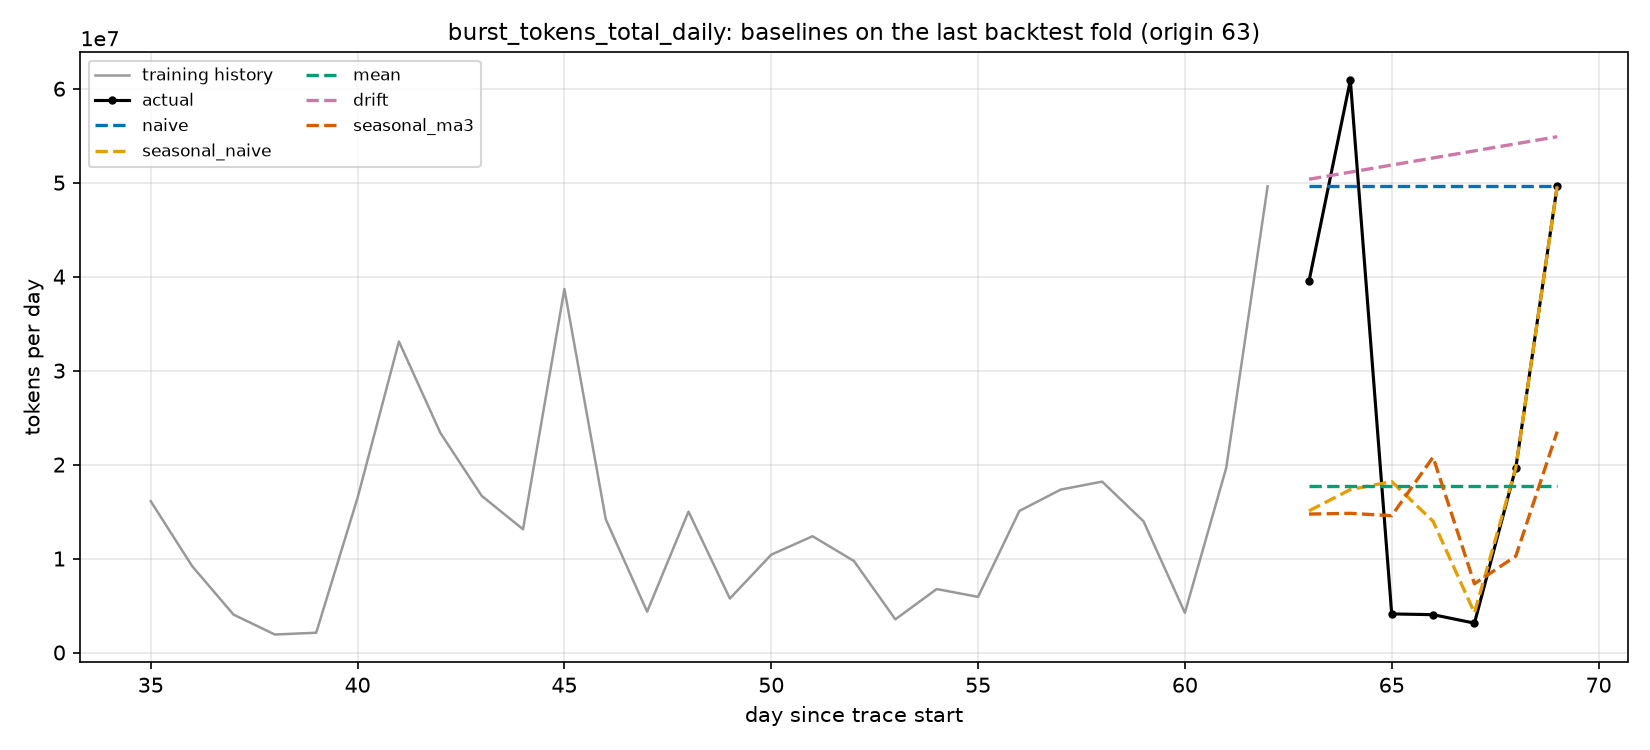

In [16]:
with step("baselines"):
    show_table(read_table("phase1", "leaderboard_baselines"), n=20)
    show_img("outputs/phase1/figures/baselines_burst_tokens_total_daily.png", width=850)

## B8. A look at the code
These cells print real functions from the project with `inspect.getsource`, so you can point to the exact
lines in the review. First **MASE**: the mean absolute error scaled by the in-sample error of seasonal naive.

In [17]:
with step("code: mase"):
    show_source("tsaf.metrics", "mase_scale")
    show_source("tsaf.metrics", "mase")

`tsaf.metrics.mase_scale`
```python
def mase_scale(train, season: int | None) -> float:
    """In-sample MAE of the seasonal naive forecast (naive when season is None or 1)."""
    y = _arr(train)
    m = season if season and season > 1 else 1
    if len(y) <= m:
        return float("nan")
    return float(np.mean(np.abs(y[m:] - y[:-m])))
```

`tsaf.metrics.mase`
```python
def mase(actual, forecast, train, season: int | None) -> float:
    """Mean absolute scaled error; NaN when the scale is 0 or cannot be computed."""
    scale = mase_scale(train, season)
    if not np.isfinite(scale) or scale == 0:
        return float("nan")
    return mae(actual, forecast) / scale
```

**Semi-averages trend**: split the series in two halves, take each half's mean, and divide the
difference by the distance between the two half centres.

In [18]:
with step("code: semi-averages"):
    show_source("tsaf.eda", "semi_averages")

`tsaf.eda.semi_averages`
```python
def semi_averages(y: np.ndarray) -> tuple[float, float]:
    """Semi-average trend: (slope, intercept). With odd n the middle point is dropped."""
    y = np.asarray(y, dtype=float)
    t = np.arange(len(y), dtype=float)
    half = len(y) // 2
    t1, y1 = t[:half], y[:half]
    t2, y2 = t[len(y) - half:], y[len(y) - half:]
    slope = (y2.mean() - y1.mean()) / (t2.mean() - t1.mean())
    return float(slope), float(y1.mean() - slope * t1.mean())
```

**Rolling-origin backtest**: every fold trains only on the data before its origin and tests on the next
h points; the origin then moves forward by `step`. No shuffling, so the future never leaks into training.

In [19]:
with step("code: rolling origin"):
    show_source("tsaf.backtest", "rolling_origin")

`tsaf.backtest.rolling_origin`
```python
def rolling_origin(series: pd.Series, forecaster: Callable, h: int, initial: int, step: int,
                   max_folds: int | None, season: int | None) -> pd.DataFrame:
    """Run `forecaster` over expanding-window folds; tidy rows per fold and step ahead."""
    rows = []
    for fold, origin in enumerate(fold_origins(len(series), initial, h, step, max_folds)):
        train, test = series.iloc[:origin], series.iloc[origin:origin + h]
        fc = np.asarray(forecaster(train, h, season), dtype=float)
        for k in range(h):
            rows.append({"fold": fold, "step_ahead": k + 1, "origin_index": origin,
                         "time": test.index[k], "actual": float(test.iloc[k]),
                         "forecast": float(fc[k])})
    cols = ["fold", "step_ahead", "origin_index", "time", "actual", "forecast"]
    return pd.DataFrame(rows, columns=cols)
```

# Summary

The talking points and limitations below are taken directly from `PHASE1_SUMMARY.md`,
so every number comes from the run.

In [20]:
with step("summary"):
    for title in ("What to say in the review", "Limitations"):
        text = md_section("outputs/phase1/PHASE1_SUMMARY.md", title)
        display(Markdown(f"### Phase 1: {title}\n\n" + (text or "_Section not found._")))

### Phase 1: What to say in the review

Phase 1 analysed 7 drivers with five benchmark forecasts and an expanding-window backtest. Variability differs a lot: burst_requests_hourly has a coefficient of variation of 1.70, while ppi_hosting_monthly has 0.06, so one model will not fit both. The rolling-std rule chose multiplicative for burst_tokens_total_daily, burst_tokens_api_daily, wildchat_conversations_daily, eci_wages_quarterly, ppi_hosting_monthly and additive for the rest. The strongest seasonality is in burst_tokens_chat_daily (STL seasonal strength 0.72). ADF and KPSS together give: burst_tokens_total_daily d=0, D=0, burst_tokens_api_daily d=0, D=0, burst_tokens_chat_daily d=0, D=1, burst_requests_hourly d=0, D=1, wildchat_conversations_daily d=0, D=1, eci_wages_quarterly d=1, D=1, ppi_hosting_monthly d=1, D=1. Best-baseline CV MASE is below 1 (better than in-sample seasonal naive) for 5 of 7 drivers; these MASE values are the bar Phase 2 must beat. For BurstGPT total tokens the least-squares trend is +0.89% of the mean per day. The day-77 outage check is FAIL: the residual screen does not separate a known outage from API bursts (see the finding below).

### Phase 1: Limitations

- BurstGPT has no calendar dates: time is days/hours since the trace started.
- The weekend (day_of_cycle 4-5) is inferred from lower volume, not known.
- The BurstGPT modelling window is only 87 days (12 weeks), so yearly effects cannot be seen.
- WildChat users are hashed IPs, an imperfect user ID; only 5 of 86 shards are downloaded.
- EDA decisions (d, D, decomposition) use the whole window including the hold-out.
- `burst_requests_hourly`: the 8 capped folds test positions 336-863 of the 1920 pre-hold-out points, not the most recent ones.
- Skipped drivers (reasons in section 1): `wildchat_conversations_weekly`, `wildchat_new_users_weekly`, `wildchat_returning_share_weekly`, `epoch_cheapest_price_monthly`.

In [21]:
with step("what we have"):
    display(Markdown("### What we have so far"))
    display(pd.DataFrame([{"phase": "1. exploration and baselines", "built": "loaders, decomposition, trend methods, ADF/KPSS, ACF/PACF, anomaly screen, 5 baselines, backtest", "outputs": "outputs/phase1: tables, figures, handoff.json, PHASE1_SUMMARY.md", "notebook": "TSAF_Phase1.ipynb"}]))

### What we have so far

,phase,built,outputs,notebook
0,1. exploration and baselines,"loaders, decomposition, trend methods, ADF/KPSS, ACF/PACF, anomaly screen, 5 baselines...","outputs/phase1: tables, figures, handoff.json, PHASE1_SUMMARY.md",TSAF_Phase1.ipynb


**Next: Phase 2** (`TSAF_Phase2.ipynb`) fits smoothing, ARIMA, machine-learning and ensemble models and compares them with the same backtest; it reads `outputs/phase1/handoff.json` from the bundle.